# 03 M0 / M1: deep hedging without costs (GBM)
M0: quadratic loss, should recover the BS delta and price. M1: CVaR loss at two levels alpha.

In [ ]:
# notebooks live in notebooks/, the project modules in the repo root
import sys
if '..' not in sys.path:
    sys.path.insert(0, '..')

%load_ext autoreload
%autoreload 2

# standard libraries
import math

# third-party
import numpy as np
import pandas as pd
import torch
import seaborn as sns
from matplotlib import pyplot as plt

# project modules
import benchmarks as bm
from model import Policy
from market.simulators import simulate_heston, simulate_gbm, HestonParams
from market.pricing import bs_price, bs_delta, bs_gamma, heston_price
from features import nn_policy
from train import train
from objectives import CVaRLoss


# Check on Features & Models


## No cost, NN and BS_Delta

*Pipeline check: an untrained network as a policy gives shape (B,) and a P&L with requires_grad = True.*

In [ ]:
model = Policy(d_in=2, m_out=1)
S = simulate_gbm(1000)["S"][:, :, 0]
T = 30 / 365

pol = nn_policy(model, 100.0, T)
print(pol(S[:, 0], T, None).shape)               

pnl = bm.hedge_pnl(S, pol, 100.0, T, c=0.0)
print(pnl.shape, pnl.requires_grad)                

torch.Size([1000])
torch.Size([1000]) True


*M0: train Policy(2, 1) with quadratic loss and a learnable premium p0.*

In [ ]:
model = Policy(d_in=2, m_out=1)
out = train(model, 100.0, 30/365)
model, p0, losses = out['model'], out['p0'], out['losses']

step: 0, loss: 17.294692993164062, p0: 0.0
step: 100, loss: 3.9909539222717285, p0: 0.9146696925163269
step: 200, loss: 0.9349364042282104, p0: 1.572177529335022
step: 300, loss: 0.40228018164634705, p0: 1.971832275390625
step: 400, loss: 0.2687132954597473, p0: 2.169276714324951
step: 500, loss: 0.21329958736896515, p0: 2.250927686691284
step: 600, loss: 0.19776852428913116, p0: 2.27738881111145
step: 700, loss: 0.1830417811870575, p0: 2.2849583625793457
step: 800, loss: 0.16409501433372498, p0: 2.2871346473693848
step: 900, loss: 0.1694793850183487, p0: 2.2867822647094727
step: 1000, loss: 0.16087551414966583, p0: 2.2864797115325928
step: 1100, loss: 0.15326237678527832, p0: 2.2860629558563232
step: 1200, loss: 0.1492050737142563, p0: 2.2853927612304688
step: 1300, loss: 0.148079052567482, p0: 2.28741192817688
step: 1400, loss: 0.13785476982593536, p0: 2.2880873680114746
step: 1500, loss: 0.14085614681243896, p0: 2.286055088043213
step: 1600, loss: 0.14132943749427795, p0: 2.28795146

*M0 test set: NN vs BS delta P&L statistics (p0 should be close to the BS price 2.29).*

In [34]:
K, T, sigma = 100.0, 30/365, 0.2

with torch.no_grad():
    S_test = simulate_gbm(100_000)["S"][:, :, 0]
    pnl_nn = bm.hedge_pnl(S_test, nn_policy(model, K, T), K, T, p0 = p0.item())
    pnl_bs = bm.hedge_pnl(S_test, bm.bs_delta_policy(K, sigma), K, T, p0 = p0.item())

pd.DataFrame({
    "NN": bm.summarize(pnl_nn),
    "BS": bm.summarize(pnl_bs),
})


,NN,BS
mean,-0.003968,-0.003633
std,0.370533,0.358962
VaR,0.609747,0.596758
CVaR,0.843331,0.840230


*M0: learned delta vs S at several times to maturity, overlaid on the BS delta N(d1).*

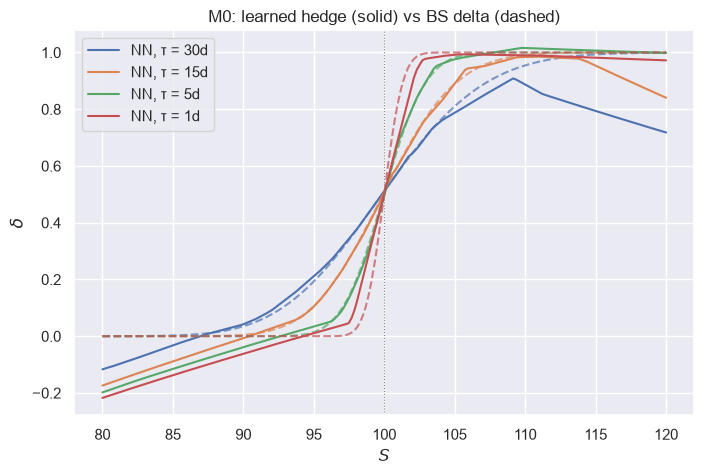

In [36]:
S_grid = torch.linspace(80, 120, 200)
taus_days = [30, 15, 5, 1]

pol_nn = nn_policy(model, K, T)
pol_bs = bm.bs_delta_policy(K, sigma)

nn_curve, bs_curve = [], []
with torch.no_grad():
    for d in taus_days:
        nn_curve.append(pol_nn(S_grid, d / 365, None))
        bs_curve.append(pol_bs(S_grid, d / 365, None))

fig, ax = plt.subplots(figsize=(8, 5))
for i, d in enumerate(taus_days):
    ax.plot(S_grid, nn_curve[i], color=f"C{i}", label=f"NN, τ = {d}d")
    ax.plot(S_grid, bs_curve[i], color=f"C{i}", ls="--", alpha=0.7)

ax.axvline(K, color="gray", lw=0.8, ls=":")
ax.set_xlabel("$S$")
ax.set_ylabel(r"$\delta$")
ax.set_title("M0: learned hedge (solid) vs BS delta (dashed)")
ax.legend()
plt.show()

## No cost, under cVaR

*M1: train one network per alpha in {0.5, 0.99} with the CVaR loss (w learned jointly).*

In [ ]:
s_scale = sigma * (T ** 0.5)      # ≈ 0.057

result = []
for alpha in [0.5, 0.99]:
    model = Policy(d_in=2, m_out=1)
    cvar = CVaRLoss(alpha)
    out = train(model, K, T, loss_fn=cvar, s_scale=s_scale, n_steps=3000)
    result.append(out)

step: 0, loss: 4.92167329788208
step: 100, loss: 3.510335683822632
step: 200, loss: 2.6900827884674072
step: 300, loss: 2.5520286560058594
step: 400, loss: 2.561441421508789
step: 500, loss: 2.5522191524505615
step: 600, loss: 2.5565550327301025
step: 700, loss: 2.5586225986480713
step: 800, loss: 2.565028429031372
step: 900, loss: 2.5506367683410645
step: 1000, loss: 2.565237045288086
step: 1100, loss: 2.5591213703155518
step: 1200, loss: 2.5522518157958984
step: 1300, loss: 2.5518124103546143
step: 1400, loss: 2.553675413131714
step: 1500, loss: 2.547689914703369
step: 1600, loss: 2.5563440322875977
step: 1700, loss: 2.5565643310546875
step: 1800, loss: 2.560689926147461
step: 1900, loss: 2.5618977546691895
step: 2000, loss: 2.5564258098602295
step: 2100, loss: 2.549811363220215
step: 2200, loss: 2.566432476043701
step: 2300, loss: 2.5721826553344727
step: 2400, loss: 2.5567898750305176
step: 2500, loss: 2.5559468269348145
step: 2600, loss: 2.555396318435669
step: 2700, loss: 2.54748

*M1 test set: price = CVaR_alpha of the loss for NN and BS delta; learned w should match the VaR.*

In [64]:
def eval_pol(pol, alpha):
    torch.manual_seed(0)
    S_test = simulate_gbm(100_000)['S'][:, :, 0]
    pnl = bm.hedge_pnl(S_test, pol, K, T)
    p0_star = bm.summarize(pnl, alpha)["CVaR"]
    return {"p0": p0_star, **bm.summarize(pnl + p0_star, alpha)}

rows = {}
for i, alpha in enumerate([0.5, 0.99]):
    pol_nn = nn_policy(result[i]["model"], K, T, s_scale=s_scale)
    rows[f"NN {alpha}"] = eval_pol(pol_nn, alpha)
    rows[f"BS {alpha}"] = eval_pol(bm.bs_delta_policy(K, sigma), alpha)
    rows[f"NN {alpha}"]["w"] = result[i]["loss_fn"].w.item()

pd.DataFrame(rows).T

,p0,mean,std,VaR,CVaR,w
NN 0.5,2.556777,0.270188,0.359743,-0.278838,-3.028870e-08,2.27550
BS 0.5,2.556016,0.269221,0.357908,-0.273791,-2.368164e-07,NaN
NN 0.99,3.251972,0.965751,0.449841,-0.128939,6.175041e-08,3.12876
BS 0.99,3.511555,1.224760,0.357908,-0.246274,1.859665e-08,NaN


*M1: P&L histograms (linear and log scale) of NN (CVaR 0.99) vs BS delta, each with its own price.*

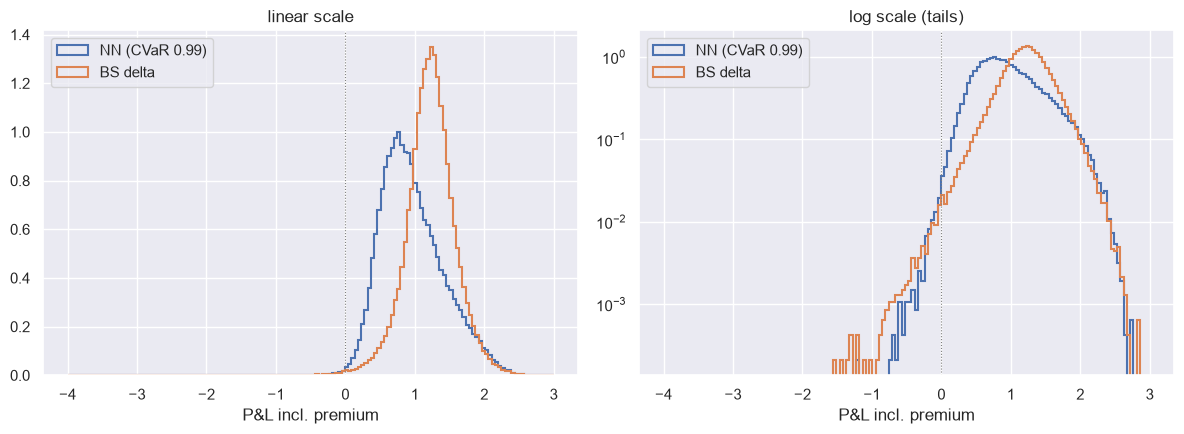

In [ ]:
alpha = 0.99
with torch.no_grad():
    torch.manual_seed(0)
    S_test = simulate_gbm(100_000)["S"][:, :, 0]
    pnl_nn = bm.hedge_pnl(S_test, nn_policy(result[1]["model"], K, T, s_scale=s_scale), K, T)
    pnl_bs = bm.hedge_pnl(S_test, bm.bs_delta_policy(K, sigma), K, T)

curves = {}
for name, pnl in [("NN (CVaR 0.99)", pnl_nn), ("BS delta", pnl_bs)]:
    p0 = bm.summarize(pnl, alpha)["CVaR"]
    curves[name] = (pnl + p0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.linspace(-4, 3, 150)
for ax, logy in zip(axes, [False, True]):
    for name, x in curves.items():
        ax.hist(x, bins=bins, histtype="step", lw=1.5, label=name, density=True)
    ax.axvline(0, color="gray", lw=0.8, ls=":")
    ax.set_xlabel("P&L incl. premium")
    if logy:
        ax.set_yscale("log")
        ax.set_title("log scale (tails)")
    else:
        ax.set_title("linear scale")
    ax.legend()
plt.tight_layout()
plt.show()